# 06 · The `amrpredict` library

**Forecasting Antibiotic Resistance with AI** · Final Year Project · Hamza Afzal (models), Muhammad Ali Mirza (data and evolution), Suleman Saleh (platform)

The project's models as a Python package on PyPI: **https://pypi.org/project/amrpredict/**. This notebook was run in a **new, empty virtual environment** with only

```
pip install amrpredict
```

so it shows exactly what anyone gets from PyPI: the same models and the same answers as the website, with no project files. Run time: under a minute, plus about 10 seconds to download one genome from BV-BRC.

| Function | Model | Website page |
|---|---|---|
| `forecast()` | Forecaster (LightGBM) | `/forecast` |
| `predict_fasta()` | Gene model with AMRFinderPlus, else k-mer model (LightGBM) | `/predict` |
| `identify_species()` | 6-mer species profiles | `/predict` |
| `forecast_trend()`, `trend_series()` | Timeline ML model (LightGBM) | `/timeline` |
| `plan_treatment()` | RL agent (PPO), trained on the simulation | `/timeline` |
| `simulate_timeline()` | Biological simulation, **not a trained model** | `/timeline` |
| `antibiotics()`, `status()` | What each model knows, and which models loaded | |

In [1]:
import sys, amrpredict
print('amrpredict', amrpredict.__version__, '| Python', sys.version.split()[0], '|', amrpredict.__file__)

amrpredict 0.3.0 | Python 3.13.12 | C:\Users\HP\AppData\Local\Temp\pypitest\Lib\site-packages\amrpredict\__init__.py


## 1. Which models loaded

The models are bundled inside the package; nothing is read until the first call.

In [2]:
import pandas as pd
st = amrpredict.status()
pd.DataFrame([{'model': k, 'trained': v.get('trained'), 'type': v.get('model_type', v.get('description', ''))[:70]}
              for k, v in st.items() if isinstance(v, dict)])

,model,trained,type
0,lgbm_forecasting,True,LightGBM Gradient Boosting
1,genome_resistance,True,LightGBM on 4-mer frequencies of the complete ...
2,trend_forecast,True,LightGBM on yearly resistant shares (BV-BRC la...
3,rl_agent,True,PPO (stable-baselines3)
4,mutation_timeline,False,Biological Simulation


In [3]:
{m: len(amrpredict.antibiotics(model=m)) for m in ['forecast', 'genome', 'trend', 'rl']}

{'forecast': 126, 'genome': 111, 'trend': 89, 'rl': 3}

## 2. Forecaster: will this isolate resist? (`/forecast`)

From lab metadata: the antibiotic, the organism (NCBI taxon ID; 562 is *E. coli*) and an MIC reading. The first call gives **Resistant, P = 0.7055**, the same as the website's `/forecast` for the same input.

In [4]:
rows = []
for drug, taxon, mic in [('ciprofloxacin', 562, 4), ('ciprofloxacin', 562, 0.015), ('ampicillin', 562, 32), ('meropenem', 573, 0.25)]:
    r = amrpredict.forecast(drug, taxon_id=taxon, mic_value=mic)
    rows.append({'antibiotic': drug, 'taxon': taxon, 'MIC': mic, 'prediction': r['prediction'],
                 'probability': r['probability'], 'model': r['model_run']})
pd.DataFrame(rows)

,antibiotic,taxon,MIC,prediction,probability,model
0,ciprofloxacin,562,4.000,Resistant,0.7055,D3_forecaster_deploy_v7
1,ciprofloxacin,562,0.015,Susceptible,0.0034,D3_forecaster_deploy_v7
2,ampicillin,562,32.000,Resistant,0.9973,D3_forecaster_deploy_v7
3,meropenem,573,0.250,Susceptible,0.0744,D3_forecaster_deploy_v7


## 3. Genome models: will this genome resist? (`/predict`)

A complete genome assembly: *Salmonella enterica*, BV-BRC genome **108619.160**, which is in the **test set** of both genome models (no model trained on it). It is downloaded from BV-BRC, the public database the project's data comes from. Its laboratory results are listed beside the predictions.

On a laptop without NCBI AMRFinderPlus (Windows, for example), `predict_fasta()` uses the **k-mer model** (lab AUC 0.935). With AMRFinderPlus installed (Linux or macOS, through conda) it uses the gene model (lab AUC 0.977).

In [5]:
import os, urllib.request
GENOME_ID = '108619.160'
path = f'{GENOME_ID}.fna'
if not os.path.exists(path):
    url = f'https://www.bv-brc.org/api/genome_sequence/?eq(genome_id,{GENOME_ID})&limit(100000)'
    req = urllib.request.Request(url, headers={'Accept': 'application/dna+fasta', 'User-Agent': 'amrpredict-demo/1.0'})
    with urllib.request.urlopen(req, timeout=120) as r, open(path, 'wb') as fh:
        fh.write(r.read())
fasta = open(path).read()
print(f'{fasta.count(">")} contig(s), {sum(len(l) for l in fasta.splitlines() if not l.startswith(">")):,} bp')
print('species:', amrpredict.identify_species(fasta))

46 contig(s), 4,909,643 bp


species: {'species': 'Salmonella enterica', 'genus': 'Salmonella', 'distance': 0.00022}


In [6]:
# Laboratory results for this genome (BV-BRC, cleaned table v7)
LAB = {'amoxicillin/clavulanic acid': 'Susceptible', 'ampicillin': 'Resistant', 'azithromycin': 'Susceptible',
       'cefoxitin': 'Susceptible', 'ceftiofur': 'Susceptible', 'ceftriaxone': 'Susceptible',
       'chloramphenicol': 'Resistant', 'ciprofloxacin': 'Susceptible', 'gentamicin': 'Resistant',
       'nalidixic acid': 'Susceptible', 'streptomycin': 'Resistant', 'sulfisoxazole': 'Resistant',
       'tetracycline': 'Resistant', 'trimethoprim/sulfamethoxazole': 'Resistant'}
rows = []
for drug, truth in LAB.items():
    p = amrpredict.predict_fasta(fasta, drug)
    rows.append({'antibiotic': drug, 'laboratory': truth, 'model': p['prediction'], 'probability': p['probability'],
                 'correct': '✓' if p['prediction'] == truth else '✗'})
table = pd.DataFrame(rows)
print(p['model_used'])
print(f"correct: {(table['correct'] == '✓').sum()} of {len(table)}")
table

LightGBM on 4-mers (G_kmer_deploy)
correct: 11 of 14


,antibiotic,laboratory,model,probability,correct
0,amoxicillin/clavulanic acid,Susceptible,Susceptible,0.1501,✓
1,ampicillin,Resistant,Resistant,0.5648,✓
2,azithromycin,Susceptible,Susceptible,0.0626,✓
3,cefoxitin,Susceptible,Susceptible,0.0825,✓
4,ceftiofur,Susceptible,Susceptible,0.1210,✓
5,ceftriaxone,Susceptible,Susceptible,0.1925,✓
6,chloramphenicol,Resistant,Susceptible,0.2649,✗
7,ciprofloxacin,Susceptible,Susceptible,0.1231,✓
8,gentamicin,Resistant,Susceptible,0.1868,✗
9,nalidixic acid,Susceptible,Susceptible,0.1652,✓


One genome is an illustration, not an evaluation: the k-mer model's measured performance is lab AUC 0.935 on 4,481 unseen genomes (`02_genome_models.ipynb`). Its misses here (chloramphenicol, gentamicin, co-trimoxazole) are acquired-gene resistances, which the gene model reads directly.

## 4. Timeline ML model: how will resistance change? (`/timeline`)

In [7]:
t = amrpredict.forecast_trend('Streptococcus', 'penicillin', years_ahead=5)
print(t['model_run'], '|', t['label'])
print('error on years it never saw (2017-2022):', t['metrics']['model'])
pd.DataFrame(t['forecast']).astype({'hi': float})

TL_timeline_ml | ML model trained on BV-BRC laboratory results
error on years it never saw (2017-2022): {'mae_pct': 13.98, 'ci': [11.84, 16.33]}


,year,resistant_pct,lo,hi
0,2023,14.7,0.0,39.9
1,2024,14.2,0.0,49.9
2,2025,13.9,0.0,57.6
3,2026,13.5,0.0,64.0
4,2027,13.1,0.0,69.6


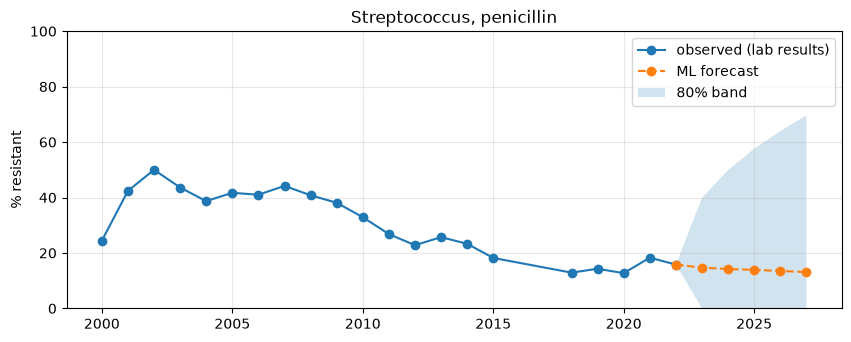

In [8]:
try:
    import matplotlib.pyplot as plt
    h, f = t['history'], t['forecast']
    plt.figure(figsize=(10, 3.6))
    plt.plot([p['year'] for p in h], [p['resistant_pct'] for p in h], 'o-', label='observed (lab results)')
    last = h[-1]
    plt.plot([last['year']] + [p['year'] for p in f], [last['resistant_pct']] + [p['resistant_pct'] for p in f], 'o--', label='ML forecast')
    plt.fill_between([last['year']] + [p['year'] for p in f], [last['resistant_pct']] + [p['lo'] for p in f],
                     [last['resistant_pct']] + [p['hi'] for p in f], alpha=0.2, label='80% band')
    plt.ylim(0, 100); plt.ylabel('% resistant'); plt.title('Streptococcus, penicillin'); plt.legend(); plt.grid(alpha=0.3)
    plt.show()
except ImportError:
    print('pip install matplotlib to draw the chart')

In [9]:
series = amrpredict.trend_series()
print(f'{len(series)} genera can be forecast, e.g. Escherichia with {len(series.get("Escherichia", []))} antibiotics')

18 genera can be forecast, e.g. Escherichia with 47 antibiotics


## 5. RL agent: which drug each week? (`/timeline`)

Trained on the simulation, not on patient data. It knows three drugs: ciprofloxacin, gentamicin and imipenem.

In [10]:
plan = amrpredict.plan_treatment('ciprofloxacin', n_weeks=52)
print('best policy:', plan['best'])
pd.DataFrame([{'policy': p['label'],
               'first failed week': p['failure_week'] if p['failure_week'] is not None else 'none in 52 weeks',
               'effective weeks (of 52)': p.get('effective_weeks'), 'first 8 weeks': ', '.join(p['policy'][:8])}
              for p in plan['policies']])

best policy: lowest_resistance


,policy,first failed week,effective weeks (of 52),first 8 weeks
0,RL agent,none in 52 weeks,52,"gentamicin, imipenem, gentamicin, imipenem, ci..."
1,Always ciprofloxacin,7,6,"ciprofloxacin, ciprofloxacin, ciprofloxacin, c..."
2,Always gentamicin,12,11,"gentamicin, gentamicin, gentamicin, gentamicin..."
3,Always imipenem,17,16,"imipenem, imipenem, imipenem, imipenem, imipen..."
4,"Cycle Ciprofloxacin → gentamicin → imipenem, e...",28,43,"ciprofloxacin, gentamicin, imipenem, ciproflox..."
5,"Cycle Ciprofloxacin → gentamicin → imipenem, e...",27,42,"ciprofloxacin, ciprofloxacin, ciprofloxacin, c..."
6,Lowest resistance first (greedy),none in 52 weeks,52,"gentamicin, gentamicin, ciprofloxacin, imipene..."


## 6. The simulation (`/timeline`, what-if)

A logistic-growth simulation with hand-set constants, labelled as such everywhere: **not a trained model**.

In [11]:
sim = amrpredict.simulate_timeline(fasta, 'ciprofloxacin', n_weeks=8)
print(sim['model_used'], '| simulation:', sim['simulation'], '| treatment fails in week', sim['failure_week'])
tl = pd.DataFrame(sim['timeline'])[['week', 'resistant_fraction', 'intermediate_fraction', 'susceptible_fraction', 'treatment_effective']]
pct = ['resistant_fraction', 'intermediate_fraction', 'susceptible_fraction']
tl[pct] = tl[pct] + 0.0          # shows a rounded -0.0 as 0.0
tl

Biological Simulation | simulation: True | treatment fails in week 4


,week,resistant_fraction,intermediate_fraction,susceptible_fraction,treatment_effective
0,0,16.87,25.00,58.13,True
1,1,23.32,25.00,51.68,True
2,2,31.47,25.00,43.53,True
3,3,40.96,25.00,34.04,True
4,4,51.04,25.00,23.96,False
5,5,60.72,25.00,14.28,False
6,6,69.18,25.00,5.82,False
7,7,75.98,24.02,0.00,False
8,8,81.08,18.92,0.00,False


## 7. The same from the command line

Installing the package also installs an `amrpredict` command. Every command prints JSON.

In [12]:
import subprocess
out = subprocess.run([sys.executable, '-m', 'amrpredict.cli', 'forecast', 'ciprofloxacin', '--taxon-id', '562', '--mic-value', '4'],
                     capture_output=True, text=True).stdout
print(out[:400])

{
  "prediction": "Resistant",
  "probability": 0.7055,
  "confidence": 70.6,
  "antibiotic": "ciprofloxacin",
  "drug_class": "fluoroquinolone",
  "threshold": 0.15,
  "model_used": "LightGBM (trained)",
  "model_run": "D3_forecaster_deploy_v7",
  "calibrated": true,
  "evidence": {
    "level": "full",
    "label": "Isolate-level estimate",
    "summary": "Based on a measured MIC and organism-sp
